In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import confusion_matrix, classification_report

%pip install seaborn

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:


# Set dataset path
base_dir = '/content/drive/MyDrive/data'

# Image preprocessing
IMG_SIZE = 224
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(rescale=1./255)
val_test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    os.path.join(base_dir, 'train'),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

val_gen = val_test_datagen.flow_from_directory(
    os.path.join(base_dir, 'valid'),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

test_gen = val_test_datagen.flow_from_directory(
    os.path.join(base_dir, 'test'),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)


Found 321 images belonging to 2 classes.
Found 81 images belonging to 2 classes.
Found 71 images belonging to 2 classes.


In [ ]:

# Load pre-trained DenseNet121 model (excluding top classification layer)
base_model = DenseNet121(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))

# Freeze the base model layers
for layer in base_model.layers:
    layer.trainable = False

# Add custom classification layers
x = base_model.output
x = GlobalAveragePooling2D()(x)  # Use GlobalAveragePooling2D instead of Flatten for DenseNet
x = Dense(1024, activation='relu')(x)  # Reduced size from 4096 to manage memory
x = Dense(1024, activation='relu')(x)
predictions = Dense(2, activation='softmax')(x)  # Assuming 2 classes: Flood, Non-Flood

# Create the new model
model = Model(inputs=base_model.input, outputs=predictions)

# Compile the model
model.compile(optimizer=Adam(learning_rate=1e-4),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Train the model
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=10  # Consistent with original notebook
)

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
 8/11 ━━━━━━━━━━━━━━━━━━━━ 17s 6s/step - accuracy: 0.6865 - loss: 0.5855

/usr/local/lib/python3.11/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


11/11 ━━━━━━━━━━━━━━━━━━━━ 128s 10s/step - accuracy: 0.7159 - loss: 0.5422 - val_accuracy: 0.9136 - val_loss: 0.2902
Epoch 2/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 64s 6s/step - accuracy: 0.9369 - loss: 0.1928 - val_accuracy: 0.8889 - val_loss: 0.1993
Epoch 3/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 90s 7s/step - accuracy: 0.9583 - loss: 0.1197 - val_accuracy: 0.9383 - val_loss: 0.1504
Epoch 4/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 67s 6s/step - accuracy: 0.9714 - loss: 0.0875 - val_accuracy: 0.9383 - val_loss: 0.1247
Epoch 5/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 66s 6s/step - accuracy: 0.9854 - loss: 0.0600 - val_accuracy: 0.9630 - val_loss: 0.1147
Epoch 6/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 67s 6s/step - accuracy: 1.0000 - loss: 0.0388 - val_accuracy: 0.9630 - val_loss: 0.1029
Epoch 7/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 67s 6s/step - accuracy: 0.9989 - loss: 0.0249 - val_accuracy: 0.9630 - val_loss: 0.1026
Epoch 8/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 74s 7s/step - accuracy: 1.0000 - loss: 0.0243 - val_accuracy: 0.9630 - val_loss: 0.1027
E

In [ ]:


# Evaluate the model
loss, accuracy = model.evaluate(test_gen)
print(f"Test Accuracy: {accuracy:.2f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 12s 3s/step - accuracy: 0.9625 - loss: 0.1681
Test Accuracy: 0.97


In [ ]:


# Save the model
model.save('/content/drive/MyDrive/pre_trained_densenet121_model.h5')
print("Model saved successfully to Google Drive.")

Model saved successfully to Google Drive.


3/3 ━━━━━━━━━━━━━━━━━━━━ 20s 5s/step


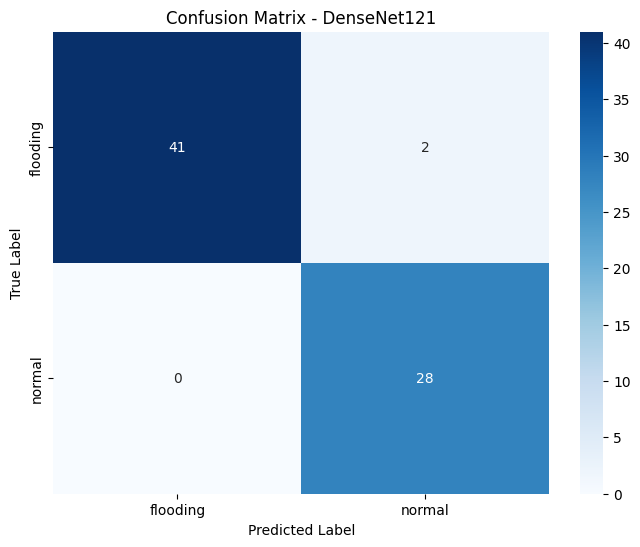

In [ ]:


# Generate and plot confusion matrix
predictions = model.predict(test_gen)
predicted_classes = np.argmax(predictions, axis=1)
true_classes = test_gen.classes
class_labels = list(test_gen.class_indices.keys())

cm = confusion_matrix(true_classes, predicted_classes)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - DenseNet121')
plt.show()



In [ ]:
# Print classification report
print("\nClassification Report:")
print(classification_report(true_classes, predicted_classes, target_names=class_labels))


Classification Report:
              precision    recall  f1-score   support

    flooding       1.00      0.95      0.98        43
      normal       0.93      1.00      0.97        28

    accuracy                           0.97        71
   macro avg       0.97      0.98      0.97        71
weighted avg       0.97      0.97      0.97        71

